# Equipment Performance Analytics

## Project Objective

Analyze mining equipment performance to understand how availability, utilization, downtime, maintenance cost, and fuel consumption relate to Overall Equipment Effectiveness (OEE), and to flag unusual equipment-days for further review.

## Analytical Scope

1. Load and validate the equipment data from the project database.
2. Summarize performance by equipment type, normalized by number of units.
3. Analyze downtime and what drives maintenance cost.
4. Compare maintenance cost and fuel intensity.
5. Examine relationships between indicators, with and without the effect of equipment type.
6. Compare autonomous and conventional haul trucks, individual units, and monthly stability.
7. Detect and validate candidate anomalies with Isolation Forest.
8. Export compact result tables.

## Data Source

Table `equipment_performance` in `mining_operations.db` (22 units, 365 days each), read directly with SQL. The notebook no longer depends on a separate `equipment_prepared.csv` file.

## Notebook Structure

| Section | Topic |
|---|---|
| 1 | Environment and data loading |
| 2 | Performance summary by equipment type |
| 3 | Downtime and OEE, and maintenance cost drivers |
| 4 | Maintenance cost and fuel intensity |
| 5 | Correlation analysis |
| 6 | Autonomous vs conventional haul trucks |
| 7 | Unit-level ranking |
| 8 | Monthly OEE stability |
| 9 | Anomaly detection |
| 10 | Export |
| 11 | Conclusion and recommendations |

> **Important note:** The dataset is synthetic and intended for portfolio demonstration. Unusual patterns require further investigation and do not automatically indicate equipment failure.

## 1. Environment and Data Loading

In [1]:
import os
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Mount Google Drive (safe to re-run)
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Locate the SQLite database in Google Drive
db_candidates = [
    Path(root) / file
    for root, dirs, files in os.walk('/content/drive/MyDrive')
    for file in files
    if file.lower() == 'mining_operations.db'
]

print("Database files found:", len(db_candidates))
for path in db_candidates:
    print(path)

if not db_candidates:
    raise ValueError("Database not found. Check its location in Google Drive.")

if len(db_candidates) > 1:
    print("\nWarning: more than one file found. The first one is used.")

DB_PATH = db_candidates[0]
OUTPUT_DIR = DB_PATH.parent / "equipment_analytics_results"
OUTPUT_DIR.mkdir(exist_ok=True)

conn = sqlite3.connect(DB_PATH)

print("\nDatabase path:", DB_PATH)
print("Output folder:", OUTPUT_DIR)

Database files found: 1
/content/drive/MyDrive/Mining-Operation/mining_operations.db

Database path: /content/drive/MyDrive/Mining-Operation/mining_operations.db
Output folder: /content/drive/MyDrive/Mining-Operation/equipment_analytics_results


In [3]:
equipment_df = pd.read_sql_query('''
    SELECT
        e.date,
        e.site_id,
        s.site_name,
        e.equipment_id,
        e.equipment_type,
        e.model,
        CASE WHEN e.autonomous = 1 THEN 'Autonomous' ELSE 'Conventional' END AS operation_mode,
        e.available_hours,
        e.operating_hours,
        e.idle_hours,
        e.maintenance_hours,
        e.breakdown_hours,
        e.availability_pct,
        e.utilization_pct,
        e.oee_pct,
        e.fuel_consumed_liters,
        e.maintenance_cost_aud
    FROM equipment_performance AS e
    INNER JOIN mine_sites AS s
        ON e.site_id = s.site_id
    ORDER BY e.equipment_id, e.date
''', conn)

equipment_df["date"] = pd.to_datetime(equipment_df["date"])
equipment_df["month"] = equipment_df["date"].dt.month

# Record type: a breakdown day takes precedence over a maintenance day
equipment_df["has_breakdown"] = equipment_df["breakdown_hours"] > 0
equipment_df["has_maintenance"] = equipment_df["maintenance_hours"] > 0
equipment_df["day_type"] = np.select(
    [equipment_df["has_breakdown"], equipment_df["has_maintenance"]],
    ["Breakdown day", "Maintenance-only day"],
    default="Normal day",
)

# Validate the loaded data before any analysis
required_columns = [
    "equipment_id", "equipment_type", "availability_pct", "utilization_pct", "oee_pct",
    "breakdown_hours", "maintenance_hours", "maintenance_cost_aud", "fuel_consumed_liters",
]
assert all(col in equipment_df.columns for col in required_columns)
assert len(equipment_df) == 8030, "Unexpected number of equipment records."
assert equipment_df["equipment_id"].nunique() == 22, "Unexpected number of equipment units."
assert equipment_df.isna().sum().sum() == 0, "Missing values found in equipment data."

print("Records:", len(equipment_df))
print("Equipment units:", equipment_df["equipment_id"].nunique())
print("Equipment types:", equipment_df["equipment_type"].nunique())
print("Date range:", equipment_df["date"].min().date(), "to", equipment_df["date"].max().date())

display(equipment_df.head())

Records: 8030
Equipment units: 22
Equipment types: 5
Date range: 2025-01-01 to 2025-12-31


,date,site_id,site_name,equipment_id,equipment_type,model,operation_mode,available_hours,operating_hours,idle_hours,maintenance_hours,breakdown_hours,availability_pct,utilization_pct,oee_pct,fuel_consumed_liters,maintenance_cost_aud,month,has_breakdown,has_maintenance,day_type
0,2025-01-01,GOLD001,Golden Valley Mine,DOZ-GV-001,Dozer,CAT D11T,Conventional,24.0,19.0,5.0,0.0,0.0,100.0,79.1,79.1,2277,1599.20,1,False,False,Normal day
1,2025-01-02,GOLD001,Golden Valley Mine,DOZ-GV-001,Dozer,CAT D11T,Conventional,24.0,18.2,5.8,0.0,0.0,100.0,75.9,75.9,2185,1685.83,1,False,False,Normal day
2,2025-01-03,GOLD001,Golden Valley Mine,DOZ-GV-001,Dozer,CAT D11T,Conventional,24.0,16.1,7.9,0.0,0.0,100.0,67.2,67.2,1935,1227.58,1,False,False,Normal day
3,2025-01-04,GOLD001,Golden Valley Mine,DOZ-GV-001,Dozer,CAT D11T,Conventional,24.0,18.8,5.2,0.0,0.0,100.0,78.4,78.4,2258,949.00,1,False,False,Normal day
4,2025-01-05,GOLD001,Golden Valley Mine,DOZ-GV-001,Dozer,CAT D11T,Conventional,24.0,17.0,7.0,0.0,0.0,100.0,70.8,70.8,2039,1337.43,1,False,False,Normal day


Data peralatan dimuat langsung dari tabel `equipment_performance` (8.030 baris, 22 unit, tanpa nilai kosong). Kolom `day_type` mengelompokkan setiap catatan menjadi hari *breakdown*, hari perawatan saja, atau hari normal, dan dipakai pada analisis berikutnya.

## 2. Performance Summary by Equipment Type

Total jam kerusakan dan biaya perawatan bergantung pada jumlah unit, sehingga ringkasan ini juga menghitung nilai **per unit** dan **per jam operasi**.

In [4]:
type_summary = (
    equipment_df.groupby("equipment_type")
    .agg(
        units=("equipment_id", "nunique"),
        records=("equipment_id", "count"),
        avg_availability_pct=("availability_pct", "mean"),
        avg_utilization_pct=("utilization_pct", "mean"),
        avg_oee_pct=("oee_pct", "mean"),
        total_operating_hours=("operating_hours", "sum"),
        total_breakdown_hours=("breakdown_hours", "sum"),
        total_maintenance_cost_aud=("maintenance_cost_aud", "sum"),
        total_fuel_liters=("fuel_consumed_liters", "sum"),
    )
    .reset_index()
)

type_summary["breakdown_hours_per_unit"] = type_summary["total_breakdown_hours"] / type_summary["units"]
type_summary["maintenance_cost_per_unit_aud"] = type_summary["total_maintenance_cost_aud"] / type_summary["units"]
type_summary["maintenance_cost_per_operating_hour_aud"] = (
    type_summary["total_maintenance_cost_aud"] / type_summary["total_operating_hours"]
)
type_summary["fuel_liters_per_operating_hour"] = (
    type_summary["total_fuel_liters"] / type_summary["total_operating_hours"]
)

type_summary = type_summary.sort_values("avg_oee_pct", ascending=False).round(2).reset_index(drop=True)

display(
    type_summary[
        ["equipment_type", "units", "records", "avg_availability_pct", "avg_utilization_pct",
         "avg_oee_pct", "total_breakdown_hours", "breakdown_hours_per_unit"]
    ]
)

,equipment_type,units,records,avg_availability_pct,avg_utilization_pct,avg_oee_pct,total_breakdown_hours,breakdown_hours_per_unit
0,Haul Truck,8,2920,98.46,85.55,84.23,370.0,46.25
1,Excavator,5,1825,98.23,81.82,80.38,306.3,61.26
2,Dozer,4,1460,98.34,75.07,73.83,222.8,55.70
3,LHD Loader,3,1095,98.10,69.97,68.63,201.3,67.10
4,Jumbo Drill,2,730,98.40,50.35,49.55,103.4,51.70


**Interpretasi**

| Jenis peralatan | Unit | OEE | Total jam kerusakan | Jam kerusakan per unit |
|---|---|---|---|---|
| Haul Truck | 8 | 84,23% | 370,0 | 46,25 |
| Excavator | 5 | 80,38% | 306,3 | 61,26 |
| Dozer | 4 | 73,83% | 222,8 | 55,70 |
| LHD Loader | 3 | 68,63% | 201,3 | 67,10 |
| Jumbo Drill | 2 | 49,55% | 103,4 | 51,70 |

- Availability hampir sama di semua jenis (sekitar 98%), sedangkan utilization dan OEE berbeda jauh. Perbedaan OEE datang dari utilization.
- **Haul Truck** memiliki OEE tertinggi dan total jam kerusakan terbanyak (370 jam), tetapi itu karena jumlah unitnya paling banyak (8). Per unit, Haul Truck justru **terendah** (46,25 jam), dan LHD Loader tertinggi (67,10 jam).
- **Jumbo Drill** memiliki OEE terendah (49,55%) meskipun jam kerusakan per unitnya bukan yang tertinggi.
- Ini temuan awal pada data sintetis, bukan bukti masalah pada peralatan tambang nyata.

## 3. Downtime and OEE

### OEE by breakdown level
Semua jam kerusakan positif pada data ini bernilai minimal 4 jam (tidak ada kerusakan singkat). Karena itu kategori dibuat dengan batas 6 jam, bukan 0–2 jam seperti pada versi sebelumnya yang menghasilkan kategori kosong.

Shortest positive breakdown (hours): 4.0


,breakdown_level,record_count,average_oee_pct,average_breakdown_hours,average_maintenance_cost_aud
0,No breakdown,7877,76.67,0.00,1804.15
1,Up to 6 hours,37,59.02,4.99,41517.63
2,Over 6 hours,116,48.58,8.79,49554.71


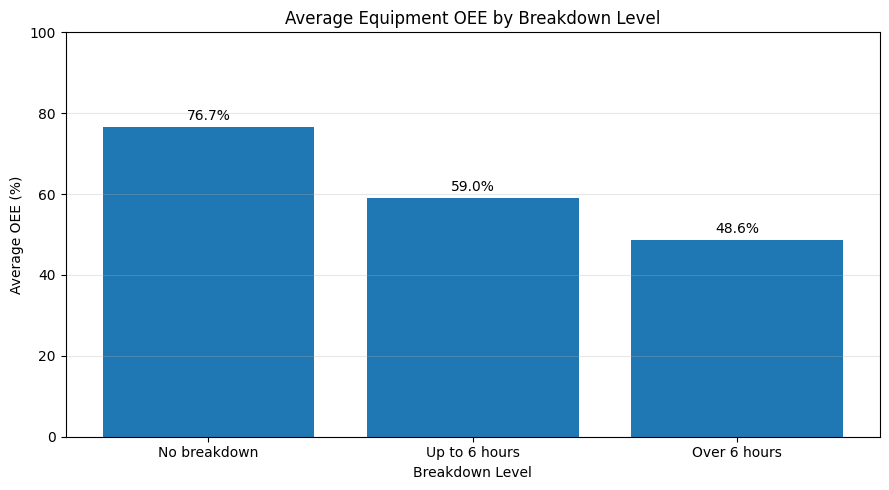

In [5]:
equipment_df["breakdown_level"] = pd.cut(
    equipment_df["breakdown_hours"],
    bins=[-0.001, 0, 6, float("inf")],
    labels=["No breakdown", "Up to 6 hours", "Over 6 hours"],
)

print("Shortest positive breakdown (hours):", equipment_df.loc[equipment_df["has_breakdown"], "breakdown_hours"].min())

breakdown_summary = (
    equipment_df.groupby("breakdown_level", observed=True)
    .agg(
        record_count=("oee_pct", "count"),
        average_oee_pct=("oee_pct", "mean"),
        average_breakdown_hours=("breakdown_hours", "mean"),
        average_maintenance_cost_aud=("maintenance_cost_aud", "mean"),
    )
    .reset_index()
    .round(2)
)
display(breakdown_summary)

plt.figure(figsize=(9, 5))
bars = plt.bar(breakdown_summary["breakdown_level"].astype(str), breakdown_summary["average_oee_pct"])
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Average Equipment OEE by Breakdown Level")
plt.xlabel("Breakdown Level")
plt.ylabel("Average OEE (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi**

| Tingkat kerusakan | Catatan | OEE rata-rata |
|---|---|---|
| Tanpa kerusakan | 7.877 | 76,67% |
| Hingga 6 jam | 37 | 59,02% |
| Di atas 6 jam | 116 | 48,58% |

Semakin lama kerusakan pada suatu hari, semakin rendah OEE hari itu. Kerusakan jarang terjadi (153 dari 8.030 catatan, sekitar 1,9%), tetapi dampaknya pada hari terjadinya besar. Ini hubungan pada data sintetis dan belum membuktikan sebab-akibat.

### What drives maintenance cost?
*(Analisis tambahan.)* Biaya perawatan dibandingkan antara hari normal, hari perawatan saja, dan hari *breakdown*.

In [6]:
day_type_order = ["Normal day", "Maintenance-only day", "Breakdown day"]

cost_by_day_type = (
    equipment_df.groupby("day_type")
    .agg(
        records=("equipment_id", "count"),
        avg_oee_pct=("oee_pct", "mean"),
        avg_maintenance_hours=("maintenance_hours", "mean"),
        avg_breakdown_hours=("breakdown_hours", "mean"),
        avg_maintenance_cost_aud=("maintenance_cost_aud", "mean"),
        total_maintenance_cost_aud=("maintenance_cost_aud", "sum"),
    )
    .reindex(day_type_order)
)

cost_by_day_type["share_of_records_pct"] = cost_by_day_type["records"] / cost_by_day_type["records"].sum() * 100
cost_by_day_type["share_of_cost_pct"] = (
    cost_by_day_type["total_maintenance_cost_aud"] / cost_by_day_type["total_maintenance_cost_aud"].sum() * 100
)

display(cost_by_day_type.round(2).reset_index())

normal_cost = cost_by_day_type.loc["Normal day", "avg_maintenance_cost_aud"]
breakdown_cost = cost_by_day_type.loc["Breakdown day", "avg_maintenance_cost_aud"]
print("Average maintenance cost on a breakdown day vs a normal day:", round(breakdown_cost / normal_cost, 1), "times")

,day_type,records,avg_oee_pct,avg_maintenance_hours,avg_breakdown_hours,avg_maintenance_cost_aud,total_maintenance_cost_aud,share_of_records_pct,share_of_cost_pct
0,Normal day,7379,77.51,0.00,0.00,1249.74,9221852.90,91.89,42.90
1,Maintenance-only day,498,64.19,3.99,0.00,10018.87,4989398.30,6.20,23.21
2,Breakdown day,153,51.10,0.18,7.87,47611.10,7284498.02,1.91,33.89


Average maintenance cost on a breakdown day vs a normal day: 38.1 times


**Interpretasi biaya perawatan**

- Hari *breakdown* hanya sekitar 1,9% dari catatan, tetapi menyumbang sekitar **34% dari total biaya perawatan** (A$7,28 juta dari A$21,50 juta). Rata-rata biayanya sekitar A$47.600 per hari, atau sekitar 38 kali hari normal (sekitar A$1.250 per hari).
- Hari perawatan saja (sekitar 6% catatan) rata-rata berbiaya sekitar A$10.000 per hari, sekitar 8 kali hari normal.
- Pengendalian kerusakan karenanya berpengaruh besar pada biaya perawatan pada data ini. Ini pola deskriptif, dan sebab-akibatnya perlu dikonfirmasi dengan catatan perawatan nyata.

## 4. Maintenance Cost and Fuel Intensity

,equipment_type,units,total_operating_hours,total_maintenance_cost_aud,maintenance_cost_per_unit_aud,maintenance_cost_per_operating_hour_aud,total_fuel_liters,fuel_liters_per_operating_hour
4,Jumbo Drill,2,8681.5,1956990.44,978495.22,225.42,520792,59.99
3,LHD Loader,3,18034.8,3053753.38,1017917.79,169.33,1442292,79.97
2,Dozer,4,25869.4,4023670.09,1005917.52,155.54,3103591,119.97
1,Excavator,5,35208.1,5099111.30,1019822.26,144.83,14082308,399.97
0,Haul Truck,8,59027.7,7362224.01,920278.00,124.72,10623509,179.97


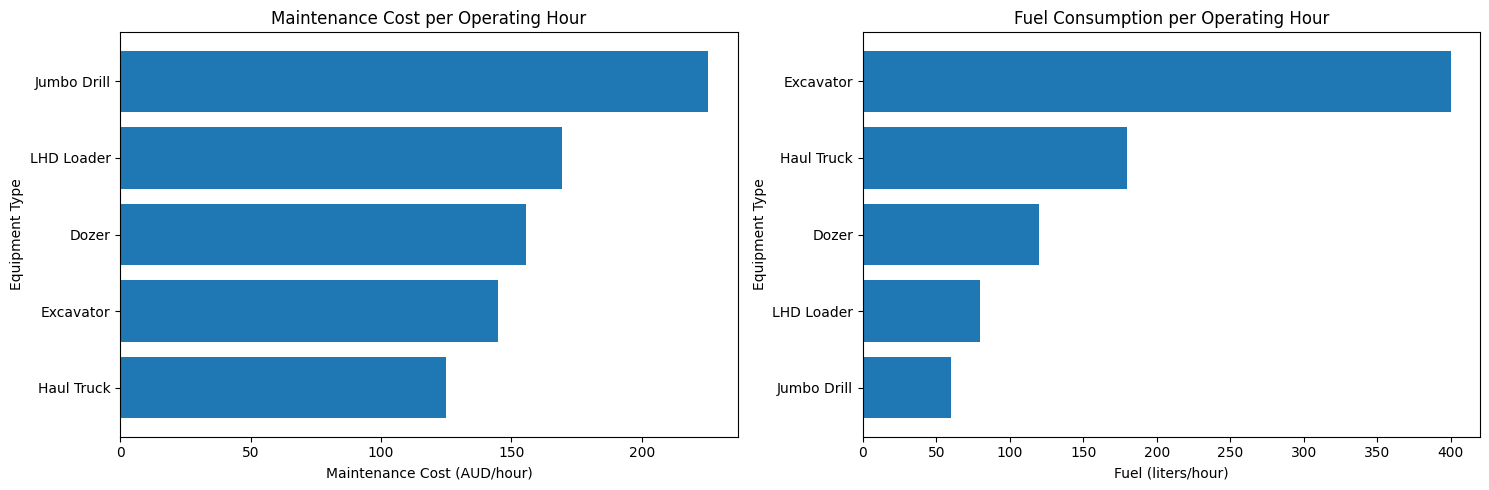

,equipment_type,mean,std,min,max
0,Dozer,119.97,0.20,119.49,120.54
1,Excavator,399.97,0.61,398.24,401.53
2,Haul Truck,179.97,0.26,179.08,181.13
3,Jumbo Drill,59.99,0.08,59.58,60.29
4,LHD Loader,79.97,0.14,79.57,80.34


In [7]:
display(
    type_summary[
        ["equipment_type", "units", "total_operating_hours", "total_maintenance_cost_aud",
         "maintenance_cost_per_unit_aud", "maintenance_cost_per_operating_hour_aud",
         "total_fuel_liters", "fuel_liters_per_operating_hour"]
    ].sort_values("maintenance_cost_per_operating_hour_aud", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cost_plot = type_summary.sort_values("maintenance_cost_per_operating_hour_aud")
axes[0].barh(cost_plot["equipment_type"], cost_plot["maintenance_cost_per_operating_hour_aud"])
axes[0].set_title("Maintenance Cost per Operating Hour")
axes[0].set_xlabel("Maintenance Cost (AUD/hour)")
axes[0].set_ylabel("Equipment Type")

fuel_plot = type_summary.sort_values("fuel_liters_per_operating_hour")
axes[1].barh(fuel_plot["equipment_type"], fuel_plot["fuel_liters_per_operating_hour"])
axes[1].set_title("Fuel Consumption per Operating Hour")
axes[1].set_xlabel("Fuel (liters/hour)")
axes[1].set_ylabel("Equipment Type")

plt.tight_layout()
plt.show()

# Is fuel use per operating hour constant within each equipment type?
fuel_rate = equipment_df["fuel_consumed_liters"] / equipment_df["operating_hours"]
display(
    fuel_rate.groupby(equipment_df["equipment_type"])
    .agg(mean="mean", std="std", min="min", max="max")
    .round(2)
    .rename_axis("equipment_type")
    .reset_index()
)

**Interpretasi**

- **Jumbo Drill** memiliki biaya perawatan per jam operasi tertinggi (sekitar A$225,42/jam). Biaya perawatan per unitnya (sekitar A$978 ribu) tidak tinggi, tetapi jam operasinya paling sedikit karena utilization rendah, sehingga biaya terbagi ke jam yang lebih sedikit. Haul Truck terendah (sekitar A$124,72/jam).
- Konsumsi bahan bakar per jam operasi hanya ditentukan oleh jenis alat: Excavator sekitar 400 L/jam, Haul Truck 180, Dozer 120, LHD Loader 80, dan Jumbo Drill 60. Di dalam satu jenis alat nilainya hampir tidak berubah (simpangan baku di bawah 1 L/jam), jadi pada dataset ini bahan bakar **hanya mengikuti jam operasi**.
- Angka ini indikator awal dari data sintetis, bukan standar efisiensi alat berat yang sebenarnya.

## 5. Correlation Analysis

Korelasi gabungan membandingkan semua catatan sekaligus, sehingga ikut terpengaruh oleh perbedaan antar jenis alat (mis. Excavator selalu boros bahan bakar dan Jumbo Drill selalu hemat). Karena itu dihitung juga korelasi **di dalam jenis alat** (setiap variabel dikurangi rata-rata jenis alatnya), untuk melihat hubungan di luar efek jenis.

=== Pooled correlation matrix ===


,breakdown_hours,maintenance_hours,utilization_pct,oee_pct,maintenance_cost_aud,fuel_consumed_liters
breakdown_hours,1.000,-0.012,-0.000,-0.261,0.851,-0.069
maintenance_hours,-0.012,1.000,-0.006,-0.239,0.257,-0.063
utilization_pct,-0.000,-0.006,1.000,0.934,-0.004,0.551
oee_pct,-0.261,-0.239,0.934,1.000,-0.289,0.549
maintenance_cost_aud,0.851,0.257,-0.004,-0.289,1.000,-0.076
fuel_consumed_liters,-0.069,-0.063,0.551,0.549,-0.076,1.000



=== Correlation with OEE ===


,pooled,within_equipment_type
maintenance_cost_aud,-0.289,-0.415
breakdown_hours,-0.261,-0.374
maintenance_hours,-0.239,-0.347
fuel_consumed_liters,0.549,0.886
utilization_pct,0.934,0.854


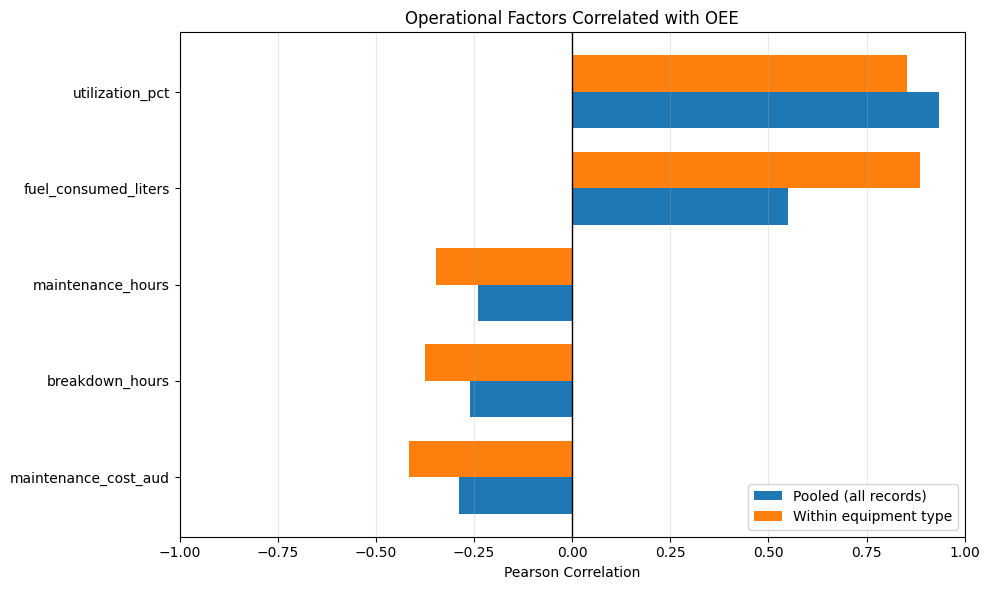

Correlation between breakdown hours and maintenance cost: 0.851


In [8]:
corr_columns = [
    "breakdown_hours", "maintenance_hours", "utilization_pct",
    "oee_pct", "maintenance_cost_aud", "fuel_consumed_liters",
]

pooled_corr = equipment_df[corr_columns].corr()

within_type = equipment_df[corr_columns] - equipment_df.groupby("equipment_type")[corr_columns].transform("mean")
within_type_corr = within_type.corr()

print("=== Pooled correlation matrix ===")
display(pooled_corr.round(3))

oee_correlation = (
    pd.DataFrame({
        "pooled": pooled_corr["oee_pct"],
        "within_equipment_type": within_type_corr["oee_pct"],
    })
    .drop(index="oee_pct")
    .sort_values("pooled")
)

print("\n=== Correlation with OEE ===")
display(oee_correlation.round(3))

positions = np.arange(len(oee_correlation))
height = 0.38

plt.figure(figsize=(10, 6))
plt.barh(positions - height / 2, oee_correlation["pooled"], height=height, label="Pooled (all records)")
plt.barh(positions + height / 2, oee_correlation["within_equipment_type"], height=height, label="Within equipment type")
plt.yticks(positions, oee_correlation.index)
plt.axvline(0, linewidth=1, color="black")
plt.title("Operational Factors Correlated with OEE")
plt.xlabel("Pearson Correlation")
plt.xlim(-1, 1)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation between breakdown hours and maintenance cost:",
      round(pooled_corr.loc["breakdown_hours", "maintenance_cost_aud"], 3))

**Interpretasi korelasi**

| Faktor | Dengan OEE (gabungan) | Dengan OEE (dalam jenis alat) |
|---|---|---|
| Utilization | +0,934 | +0,854 |
| Fuel consumed | +0,549 | +0,886 |
| Maintenance cost | −0,289 | −0,415 |
| Breakdown hours | −0,261 | −0,374 |
| Maintenance hours | −0,239 | −0,347 |

- **Utilization dan OEE** berkorelasi sangat kuat karena OEE pada dataset ini sama dengan availability × utilization (terbukti pada audit database), sehingga hubungan ini sudah pasti dan bukan temuan.
- **Bahan bakar dan OEE:** korelasi gabungan hanya sedang (0,549) karena perbedaan konsumsi antar jenis alat menutupi pola. Di dalam jenis alat korelasinya kuat (0,886), karena bahan bakar hanya mengikuti jam operasi (Section 4) dan OEE ikut naik dengan jam operasi. Ini hubungan mekanis, bukan bukti bahwa bahan bakar memengaruhi OEE.
- Faktor downtime (kerusakan, jam perawatan, biaya perawatan) berhubungan negatif dengan OEE, dan hubungannya lebih jelas setelah efek jenis alat dikeluarkan (sekitar −0,35 hingga −0,42).
- Hubungan terkuat di antara variabel biaya adalah **jam kerusakan dan biaya perawatan (+0,851)**, sesuai temuan Section 3.
- Korelasi bukan bukti sebab-akibat, dan datanya sintetis.

## 6. Autonomous vs Conventional Haul Trucks
*(Analisis tambahan.)* Haul Truck adalah satu-satunya jenis alat yang memiliki unit otonom dan konvensional.

In [9]:
haul_trucks = equipment_df[equipment_df["equipment_type"] == "Haul Truck"]

autonomy_comparison = (
    haul_trucks.groupby(["site_name", "operation_mode"])
    .agg(
        units=("equipment_id", "nunique"),
        avg_oee_pct=("oee_pct", "mean"),
        avg_utilization_pct=("utilization_pct", "mean"),
        avg_operating_hours=("operating_hours", "mean"),
        avg_breakdown_hours=("breakdown_hours", "mean"),
        avg_maintenance_cost_aud=("maintenance_cost_aud", "mean"),
        total_fuel_liters=("fuel_consumed_liters", "sum"),
        total_operating_hours=("operating_hours", "sum"),
    )
    .reset_index()
)
autonomy_comparison["fuel_liters_per_operating_hour"] = (
    autonomy_comparison["total_fuel_liters"] / autonomy_comparison["total_operating_hours"]
)

display(
    autonomy_comparison.drop(columns=["total_fuel_liters", "total_operating_hours"]).round(2)
)

,site_name,operation_mode,units,avg_oee_pct,avg_utilization_pct,avg_operating_hours,avg_breakdown_hours,avg_maintenance_cost_aud,fuel_liters_per_operating_hour
0,Golden Valley Mine,Conventional,3,78.86,80.05,18.93,0.12,2579.88,179.97
1,Iron Ridge Mine,Autonomous,3,91.64,93.17,21.99,0.15,2576.28,179.99
2,Lithium Creek Mine,Conventional,2,81.17,82.39,19.48,0.10,2351.00,179.96


**Interpretasi**

- Tiga truk otonom di Iron Ridge mencapai OEE sekitar **91,6%**, dibandingkan sekitar 78,9% (Golden Valley) dan 81,2% (Lithium Creek) pada truk konvensional.
- Selisihnya datang dari utilization (sekitar 93% vs 80–82%), yaitu truk otonom beroperasi sekitar 22 jam per hari. Jam kerusakan per catatan (sekitar 0,15) tidak lebih rendah daripada truk konvensional, dan biaya perawatan per catatan serupa. Konsumsi bahan bakar per jam operasi sama (180 L/jam).
- Keterbatasan: hanya tiga unit otonom pada satu lokasi, sehingga efek otomasi tidak bisa dipisahkan dari efek lokasi. Hasilnya indikatif.

## 7. Unit-Level Ranking
*(Analisis tambahan.)* Apakah perbedaan OEE bersumber dari jenis alat atau dari unit tertentu? Setiap unit dibandingkan dengan rata-rata jenisnya.

In [10]:
unit_ranking = (
    equipment_df.groupby(["equipment_id", "equipment_type", "site_name", "operation_mode"])
    .agg(
        avg_oee_pct=("oee_pct", "mean"),
        avg_utilization_pct=("utilization_pct", "mean"),
        total_breakdown_hours=("breakdown_hours", "sum"),
        breakdown_days=("has_breakdown", "sum"),
        total_maintenance_cost_aud=("maintenance_cost_aud", "sum"),
    )
    .reset_index()
)

type_average_oee = unit_ranking.groupby("equipment_type")["avg_oee_pct"].transform("mean")
unit_ranking["oee_gap_to_type_avg_pts"] = unit_ranking["avg_oee_pct"] - type_average_oee
unit_ranking["oee_rank_overall"] = unit_ranking["avg_oee_pct"].rank(ascending=False, method="min").astype(int)

unit_ranking = unit_ranking.sort_values("avg_oee_pct", ascending=False).round(2).reset_index(drop=True)
display(unit_ranking)

spread = (
    unit_ranking.groupby("equipment_type")["avg_oee_pct"]
    .agg(units="count", lowest="min", highest="max")
    .assign(spread_pts=lambda t: t["highest"] - t["lowest"])
    .round(2)
    .reset_index()
)
display(spread)

,equipment_id,equipment_type,site_name,operation_mode,avg_oee_pct,avg_utilization_pct,total_breakdown_hours,breakdown_days,total_maintenance_cost_aud,oee_gap_to_type_avg_pts,oee_rank_overall
0,TRK-IR-003,Haul Truck,Iron Ridge Mine,Autonomous,92.16,93.44,33.8,5,944816.50,7.93,1
1,TRK-IR-002,Haul Truck,Iron Ridge Mine,Autonomous,91.44,93.25,86.6,10,1047022.67,7.22,2
2,TRK-IR-001,Haul Truck,Iron Ridge Mine,Autonomous,91.31,92.82,45.1,5,829187.45,7.08,3
3,TRK-LC-001,Haul Truck,Lithium Creek Mine,Conventional,81.36,82.67,53.0,7,938561.34,-2.87,4
4,TRK-LC-002,Haul Truck,Lithium Creek Mine,Conventional,80.98,82.10,20.7,3,777667.15,-3.24,5
5,EXC-LC-001,Excavator,Lithium Creek Mine,Conventional,80.86,82.13,51.5,6,921532.29,0.47,6
6,EXC-GV-001,Excavator,Golden Valley Mine,Conventional,80.42,81.82,47.2,5,855625.12,0.04,7
7,EXC-IR-001,Excavator,Iron Ridge Mine,Conventional,80.28,81.73,59.1,7,1028154.19,-0.11,8
8,EXC-GV-002,Excavator,Golden Valley Mine,Conventional,80.23,82.04,96.7,14,1373489.77,-0.15,9
9,EXC-IR-002,Excavator,Iron Ridge Mine,Conventional,80.13,81.40,51.8,8,920309.93,-0.25,10


,equipment_type,units,lowest,highest,spread_pts
0,Dozer,4,73.04,74.14,1.10
1,Excavator,5,80.13,80.86,0.73
2,Haul Truck,8,78.73,92.16,13.43
3,Jumbo Drill,2,49.54,49.56,0.02
4,LHD Loader,3,68.43,68.96,0.53


**Interpretasi**

- Di dalam satu jenis alat, OEE antar unit sangat seragam: selisih tertinggi dan terendah kurang dari 2 poin untuk Dozer, Excavator, LHD Loader, dan Jumbo Drill. Perbedaan OEE jelas bersumber dari **jenis alat**, bukan dari unit tertentu.
- Satu-satunya pengecualian adalah Haul Truck, dengan rentang sekitar 13 poin. Itu berasal dari truk otonom (Section 6).
- Dua Jumbo Drill (DRL-CH-001 dan DRL-CH-002) menempati urutan terbawah, dan keduanya berada di Copper Hills.
- Karena unit dalam satu jenis serupa, prioritas tindak lanjut lebih tepat disusun per jenis alat dan per lokasi, bukan per unit.

## 8. Monthly OEE Stability
*(Analisis tambahan.)* Apakah OEE berubah sepanjang tahun?

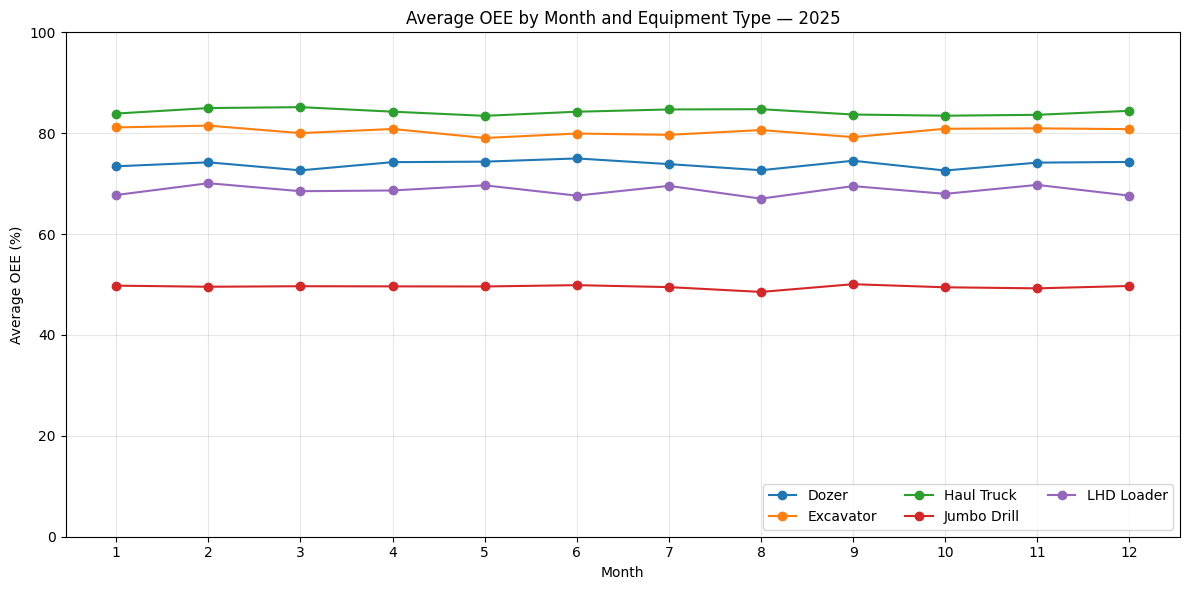

,equipment_type,lowest_month_oee,highest_month_oee,range_pts
0,Dozer,72.60,75.00,2.39
1,Excavator,79.05,81.50,2.45
2,Haul Truck,83.45,85.17,1.72
3,Jumbo Drill,48.53,50.07,1.53
4,LHD Loader,67.03,70.09,3.06


In [11]:
monthly_oee = (
    equipment_df.groupby(["month", "equipment_type"])["oee_pct"]
    .mean()
    .unstack("equipment_type")
)

plt.figure(figsize=(12, 6))
for equipment_type in monthly_oee.columns:
    plt.plot(monthly_oee.index, monthly_oee[equipment_type], marker="o", label=equipment_type)
plt.title("Average OEE by Month and Equipment Type — 2025")
plt.xlabel("Month")
plt.ylabel("Average OEE (%)")
plt.xticks(range(1, 13))
plt.ylim(0, 100)
plt.legend(ncol=3, loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "lowest_month_oee": monthly_oee.min(),
        "highest_month_oee": monthly_oee.max(),
    })
    .assign(range_pts=lambda t: t["highest_month_oee"] - t["lowest_month_oee"])
    .round(2)
    .rename_axis("equipment_type")
    .reset_index()
)

**Interpretasi**

OEE bulanan setiap jenis alat bergerak pada rentang sempit (selisih bulan tertinggi dan terendah sekitar 1,5 hingga 3 poin) tanpa tren naik atau turun yang jelas. Tidak ada pola musiman yang terlihat, dan urutan jenis alat sama sepanjang tahun. Data hanya mencakup satu tahun, sehingga musiman tidak bisa diuji lebih jauh.

## 9. Anomaly Detection

Isolation Forest dipakai untuk menandai hari-peralatan yang tidak biasa. Model ini tidak memakai label, dan jumlah catatan yang ditandai ditentukan oleh parameter `contamination` (di sini 2%, sebuah asumsi). Karena itu hasilnya diperiksa dengan tiga uji: kesesuaian dengan hari *breakdown*, sensitivitas terhadap `contamination`, dan kestabilan antar `random_state`.

### Features and model

In [12]:
from sklearn.ensemble import IsolationForest

anomaly_features = [
    "availability_pct", "utilization_pct", "oee_pct",
    "breakdown_hours", "maintenance_hours",
    "maintenance_cost_aud", "fuel_consumed_liters",
]

X_anomaly = equipment_df[anomaly_features]

iso_forest = IsolationForest(n_estimators=100, contamination=0.02, random_state=42)
equipment_df["anomaly_label"] = iso_forest.fit_predict(X_anomaly)

# Higher score = more unusual
equipment_df["anomaly_score"] = -iso_forest.score_samples(X_anomaly)
equipment_df["anomaly_status"] = np.where(equipment_df["anomaly_label"] == -1, "Potential Anomaly", "Normal")

flagged = equipment_df["anomaly_label"] == -1

print("Total records:", len(equipment_df))
print("Potential anomalies:", int(flagged.sum()), f"({flagged.mean():.1%})")

Total records: 8030
Potential anomalies: 161 (2.0%)


Catatan: `oee_pct` adalah availability × utilization (audit database), sehingga ketiganya saling redundan. Ketiganya tetap dipakai agar hasil sebanding dengan analisis sebelumnya. Model berbasis pohon tidak memerlukan penskalaan fitur.

### Check 1: What kind of days are flagged?

In [13]:
flag_by_day_type = (
    equipment_df.groupby("day_type")
    .agg(records=("equipment_id", "count"), flagged=("anomaly_label", lambda s: int((s == -1).sum())))
    .reindex(day_type_order)
)
flag_by_day_type["share_flagged_pct"] = (flag_by_day_type["flagged"] / flag_by_day_type["records"] * 100).round(1)
display(flag_by_day_type.reset_index())

breakdown_capture = flag_by_day_type.loc["Breakdown day", "flagged"] / flag_by_day_type.loc["Breakdown day", "records"]
print(f"Share of breakdown days captured by the model: {breakdown_capture:.1%}")
print("Share of flagged records that are breakdown days:",
      f"{flag_by_day_type.loc['Breakdown day', 'flagged'] / flag_by_day_type['flagged'].sum():.1%}")

,day_type,records,flagged,share_flagged_pct
0,Normal day,7379,0,0.0
1,Maintenance-only day,498,19,3.8
2,Breakdown day,153,142,92.8


Share of breakdown days captured by the model: 92.8%
Share of flagged records that are breakdown days: 88.2%


### Check 2: Sensitivity to `contamination` and stability across seeds

In [14]:
sensitivity_rows = []
for contamination in [0.01, 0.02, 0.05]:
    model = IsolationForest(n_estimators=100, contamination=contamination, random_state=42)
    labels = model.fit_predict(X_anomaly) == -1
    sensitivity_rows.append({
        "contamination": contamination,
        "flagged_records": int(labels.sum()),
        "breakdown_days_flagged": int((labels & (equipment_df["day_type"] == "Breakdown day")).sum()),
        "maintenance_only_days_flagged": int((labels & (equipment_df["day_type"] == "Maintenance-only day")).sum()),
        "normal_days_flagged": int((labels & (equipment_df["day_type"] == "Normal day")).sum()),
    })
display(pd.DataFrame(sensitivity_rows))

# Overlap between flagged sets from different random seeds (Jaccard similarity, 1 = identical)
baseline_set = set(np.where(flagged)[0])
stability_rows = []
for seed in [1, 2, 3, 99]:
    model = IsolationForest(n_estimators=100, contamination=0.02, random_state=seed)
    seed_set = set(np.where(model.fit_predict(X_anomaly) == -1)[0])
    stability_rows.append({
        "random_state": seed,
        "jaccard_vs_baseline": len(baseline_set & seed_set) / len(baseline_set | seed_set),
    })
stability_df = pd.DataFrame(stability_rows).round(2)
display(stability_df)

,contamination,flagged_records,breakdown_days_flagged,maintenance_only_days_flagged,normal_days_flagged
0,0.01,81,81,0,0
1,0.02,161,142,19,0
2,0.05,402,153,249,0


,random_state,jaccard_vs_baseline
0,1,0.91
1,2,0.85
2,3,0.91
3,99,0.91


**Interpretasi uji model**

- Model terutama menandai **hari *breakdown***: hampir seluruh hari kerusakan tertangkap, dan sebagian besar catatan yang ditandai adalah hari kerusakan. Sisanya umumnya hari perawatan dengan biaya tinggi. Model ini tidak menemukan pola baru di luar yang sudah terlihat pada Section 3, yaitu hari kerusakan memiliki OEE dan biaya yang sangat berbeda.
- `contamination` menentukan jumlah catatan yang ditandai. Pada 1% hanya hari paling ekstrem yang ditandai, sedangkan pada 5% lebih banyak hari non-*breakdown* ikut masuk. Angka 2% (161 catatan) adalah pilihan, bukan hasil yang "ditemukan" model.
- Hasil cukup stabil antar `random_state` (kemiripan sekitar 0,85 hingga 0,91), tetapi angka tepatnya dapat sedikit berbeda antar versi scikit-learn.
- Catatan yang ditandai adalah kandidat untuk ditinjau, bukan kerusakan yang terkonfirmasi.

### Top 20 flagged records

In [15]:
columns_to_show = [
    "date", "site_name", "equipment_id", "equipment_type", "availability_pct", "utilization_pct",
    "oee_pct", "breakdown_hours", "maintenance_hours", "maintenance_cost_aud", "anomaly_score",
]

top_anomalies = (
    equipment_df.loc[flagged, columns_to_show]
    .sort_values("anomaly_score", ascending=False)
    .head(20)
    .round({"anomaly_score": 3})
)
display(top_anomalies)

,date,site_name,equipment_id,equipment_type,availability_pct,utilization_pct,oee_pct,breakdown_hours,maintenance_hours,maintenance_cost_aud,anomaly_score
5324,2025-08-03,Golden Valley Mine,TRK-GV-001,Haul Truck,52.2,95.2,49.7,11.5,0.0,71337.47,0.774
6860,2025-10-18,Iron Ridge Mine,TRK-IR-002,Haul Truck,50.5,100.0,50.5,11.9,0.0,72669.96,0.772
2033,2025-07-28,Copper Hills Mine,DRL-CH-002,Jumbo Drill,59.6,50.0,29.8,9.7,0.0,62762.72,0.771
6805,2025-08-24,Iron Ridge Mine,TRK-IR-002,Haul Truck,53.7,100.0,53.7,11.1,0.0,68660.92,0.767
70,2025-03-12,Golden Valley Mine,DOZ-GV-001,Dozer,51.0,76.3,38.9,11.7,0.0,65093.82,0.766
4961,2025-08-05,Copper Hills Mine,LHD-CH-003,LHD Loader,53.0,73.0,38.6,11.3,0.0,65641.68,0.765
5587,2025-04-23,Golden Valley Mine,TRK-GV-002,Haul Truck,60.0,68.0,40.8,9.6,0.0,77286.65,0.764
413,2025-02-18,Golden Valley Mine,DOZ-GV-002,Dozer,56.5,89.8,50.8,10.4,0.0,74881.39,0.763
251,2025-09-09,Golden Valley Mine,DOZ-GV-001,Dozer,60.0,90.2,54.1,9.6,0.0,68791.08,0.763
5433,2025-11-20,Golden Valley Mine,TRK-GV-001,Haul Truck,58.9,63.4,37.4,9.9,0.0,65103.02,0.763


### Flagged records by equipment type and site

In [16]:
anomaly_by_type = (
    equipment_df.groupby("equipment_type")
    .agg(
        records=("equipment_id", "count"),
        flagged=("anomaly_label", lambda s: int((s == -1).sum())),
    )
)
anomaly_by_type["flag_rate_pct"] = (anomaly_by_type["flagged"] / anomaly_by_type["records"] * 100).round(2)

flagged_profile = (
    equipment_df[flagged]
    .groupby("equipment_type")
    .agg(
        avg_oee_pct=("oee_pct", "mean"),
        avg_breakdown_hours=("breakdown_hours", "mean"),
        avg_maintenance_cost_aud=("maintenance_cost_aud", "mean"),
    )
    .round(2)
)

display(anomaly_by_type.join(flagged_profile).sort_values("flagged", ascending=False).reset_index())

anomaly_by_site = (
    equipment_df.groupby("site_name")
    .agg(
        records=("equipment_id", "count"),
        flagged=("anomaly_label", lambda s: int((s == -1).sum())),
    )
)
anomaly_by_site["flag_rate_pct"] = (anomaly_by_site["flagged"] / anomaly_by_site["records"] * 100).round(2)
display(anomaly_by_site.reset_index())

,equipment_type,records,flagged,flag_rate_pct,avg_oee_pct,avg_breakdown_hours,avg_maintenance_cost_aud
0,Excavator,1825,45,2.47,57.24,6.60,40612.93
1,Haul Truck,2920,43,1.47,55.59,8.37,50332.98
2,Jumbo Drill,730,26,3.56,36.48,3.82,31170.51
3,Dozer,1460,24,1.64,49.59,8.31,52842.43
4,LHD Loader,1095,23,2.10,44.54,8.56,47426.75


,site_name,records,flagged,flag_rate_pct
0,Copper Hills Mine,1825,49,2.68
1,Golden Valley Mine,2555,52,2.04
2,Iron Ridge Mine,2190,39,1.78
3,Lithium Creek Mine,1460,21,1.44


**Interpretasi**

Tingkat penandaan per jenis alat dan per lokasi berbeda-beda, tetapi sebagian besar mencerminkan jumlah hari kerusakan di masing-masing kelompok. Perbedaan ini sebaiknya dibaca bersama jumlah unit dan jam operasi, dan tidak menunjukkan jenis alat atau lokasi tertentu bermasalah.

## 10. Export

Hasil analisis diekspor ke tiga file CSV di folder `equipment_analytics_results`. Ringkasan per jenis alat digabung menjadi satu file, dan hasil deteksi anomali disimpan dalam satu file berstatus (tanpa file terpisah untuk catatan yang ditandai saja, karena dapat disaring dari kolom `anomaly_status`).

In [17]:
export_files = {
    "equipment_type_summary.csv": type_summary,
    "equipment_breakdown_level_summary.csv": breakdown_summary,
    "equipment_anomaly_results.csv": equipment_df[
        ["date", "site_id", "site_name", "equipment_id", "equipment_type", "operation_mode"]
        + anomaly_features
        + ["day_type", "anomaly_score", "anomaly_status"]
    ].round({"anomaly_score": 4}),
}

for file_name, table in export_files.items():
    table.to_csv(OUTPUT_DIR / file_name, index=False)

# Read the files back to verify them
verification = pd.DataFrame([
    {
        "file": file_name,
        "rows_expected": len(table),
        "rows_in_file": len(pd.read_csv(OUTPUT_DIR / file_name)),
        "columns": table.shape[1],
    }
    for file_name, table in export_files.items()
])
verification["match"] = verification["rows_expected"] == verification["rows_in_file"]
display(verification)

assert verification["match"].all(), "An exported file does not match its source table."
print("Files in the output folder:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

,file,rows_expected,rows_in_file,columns,match
0,equipment_type_summary.csv,5,5,14,True
1,equipment_breakdown_level_summary.csv,3,3,5,True
2,equipment_anomaly_results.csv,8030,8030,16,True


Files in the output folder: ['equipment_anomaly_results.csv', 'equipment_breakdown_level_summary.csv', 'equipment_type_summary.csv']


## 11. Conclusion and Operational Recommendations

### Key Findings

- **OEE differs by equipment type, not by unit.** Haul Trucks lead (84.23%) and Jumbo Drills trail (49.55%). Units of the same type perform almost identically, and monthly OEE is stable through the year. Availability is about 98% for every type, so the differences come from utilization.
- **Totals depend on fleet size.** Haul Trucks record the most breakdown hours in total (370) but the fewest per unit (46.25), while LHD Loaders record the most per unit (67.10).
- **Breakdowns drive maintenance cost.** Breakdown days are about 1.9% of records but account for about 34% of maintenance cost, at roughly 38 times the cost of a normal day. Breakdown hours and maintenance cost correlate at +0.85.
- **Fuel follows operating hours.** Fuel use per operating hour is fixed for each equipment type, so fuel consumption mainly reflects how long equipment runs.
- **Pooled correlations hide the type effect.** Downtime factors relate to OEE more clearly within equipment types (about −0.35 to −0.42) than across all records (about −0.24 to −0.29). The utilization–OEE correlation is by construction, because OEE equals availability × utilization in this dataset.
- **Autonomous haul trucks stand out.** The three autonomous trucks at Iron Ridge reach about 91.6% OEE versus about 79–81% for conventional trucks, driven by higher utilization rather than fewer breakdowns. This rests on three units at one site.
- **Anomaly detection mostly finds breakdown days.** Isolation Forest flags about 2% of records (a chosen threshold), mainly breakdown days. Results are stable across random seeds but depend on the contamination setting.

### Operational Recommendations

1. Focus on reducing the frequency and duration of breakdowns, since they account for a disproportionate share of maintenance cost.
2. Investigate why Jumbo Drill utilization is low (about 50%), keeping in mind both Jumbo Drills and LHD Loaders operate only at Copper Hills.
3. Assess whether the autonomous haul-truck utilization advantage holds across more units and sites.
4. Review flagged equipment-days against actual maintenance logs before making maintenance decisions.
5. Record planned and unplanned downtime separately so downtime can be analyzed more precisely.

### Limitations

This project uses a synthetic dataset for portfolio demonstration. Fuel use per hour is constant within each type, OEE has no performance or quality component, only one year of data is available, and only 22 units are tracked. The findings should not be interpreted as actual mine-site performance or confirmed equipment failures.

### Tools and Methods

Python, SQLite, Pandas, NumPy, Matplotlib, correlation analysis, within-group analysis, and Isolation Forest (scikit-learn).